In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from functools import reduce
import matplotlib.pyplot as plt

plt.rcParams.update({
  "font.size": 9,
  "axes.titlesize": 9,
  "axes.labelsize": 9,
  "xtick.labelsize": 9,
  "ytick.labelsize": 9,
  "legend.fontsize": 9
})

# Carrier influences

In [3]:
def p_to_stars(p):
  if p < 1e-4:
    return "****"
  elif p < 1e-3:
    return "***"
  elif p < 1e-2:
    return "**"
  elif p < 0.05:
    return "*"
  else:
    return "ns"

In [4]:
def expand_time(weights, time_step = 0.025, sample_time_step = 0.5, max_time = None):
  synapse_cols = [ f"Synapse{id}" for id in range(0, 10) ]
  time = weights.Time
  weights_to_update = weights.copy()[ synapse_cols ]

  if max_time is None:
    max_time = time.max()

  time = (time / time_step).round() * time_step
  weights_to_update.index = time

  new_time = np.arange(0, max_time + time_step, time_step)
  new_weights = pd.DataFrame(weights_to_update).set_index(time).reindex(new_time, method = "ffill")

  if time_step == sample_time_step:
    return new_weights

  # sample every sample_time_step
  sampled_time = np.arange(0, max_time, sample_time_step)
  new_weights = new_weights.loc[sampled_time]

  return new_weights

In [5]:
def read_weights(stimulation):
  cell_ids = np.arange(0, 20)
  frequency = 5

  weights = []
  for cell_id in cell_ids:
    filename = f"output/temporal-interference-1/{cell_id}/random_poisson/{frequency}/{stimulation}/synapse_weights.csv"
    synapse_weights = pd.read_csv(filename, index_col = 0)
    synapse_weights = expand_time(synapse_weights, time_step = 0.025, sample_time_step = 0.025, max_time = 10_000)

    synapse_columns = [ f"Synapse{id}" for id in range(0, 10) ]
    synapse_weights = synapse_weights.rename(columns = { synapse: f"{synapse}_cell{cell_id}" for synapse in synapse_columns })

    weights.append(synapse_weights)
  
  weights = reduce(lambda left, right: pd.merge(left, right, on = "Time", how = "inner"), weights)

  return weights

In [23]:
carrier = 1000
beat = 5
frequency = 5
synapse_cols = [f"Synapse{idx}" for idx in range(0, 10)]

stimulations = [
  "No tTIS",
  "1000 Hz carrier"
]

stimulations_dict = {
  "noTI_0.1": "No tTIS",
  "1000_0_0.26_0.1": "1000 Hz carrier"
}

colors = {
  "No tTIS": "#0D0887",
  "1000 Hz carrier": "#E16462"
}

weights = {
  "No tTIS": read_weights("noTI_0.1"),
  "1000 Hz carrier": read_weights("1000_0_0.26_0.1")
}

In [8]:
def categorize(w, atol = 1e-4):
  if w > 0.1 + atol: return "LTP"
  if w < 0.1 - atol: return "LTD"
  return "Stable"

order = ["LTP", "Stable", "LTD"]

In [9]:
weight_categories = []

for stimulation in weights.keys():
  w = weights[stimulation]
  
  time_select = np.where(w.index >= 9.5 * 1000)[0]
  final_weights = w.iloc[ time_select ].mean(axis = 0).tolist()

  categories = pd.DataFrame({
    "Stimulation": stimulation,
    "Weight": final_weights,
    "SynapseID": w.columns,
    "Category": [ categorize(w_) for w_ in final_weights ]
  })

  categories["Category"] = pd.Categorical(categories["Category"], categories = order, ordered = True)

  weight_categories.append(categories)

weight_categories = pd.concat(weight_categories, ignore_index = True)
weight_categories

,Stimulation,Weight,SynapseID,Category
0,No tTIS,0.199465,Synapse0_cell0,LTP
1,No tTIS,0.452394,Synapse1_cell0,LTP
2,No tTIS,0.080258,Synapse2_cell0,LTD
3,No tTIS,0.761628,Synapse3_cell0,LTP
4,No tTIS,0.468787,Synapse4_cell0,LTP
...,...,...,...,...
395,1000 Hz carrier,0.100000,Synapse5_cell19,Stable
396,1000 Hz carrier,0.100000,Synapse6_cell19,Stable
397,1000 Hz carrier,0.259850,Synapse7_cell19,LTP
398,1000 Hz carrier,0.551641,Synapse8_cell19,LTP


In [10]:
def format_ax(ax, grid = True):
  ax.spines["top"].set_visible(False)
  ax.spines["right"].set_visible(False)

  for spine in ax.spines.values():
    spine.set_color("gray")

  ax.tick_params(axis="both", colors="#1a1a1a")

  if grid:
    ax.grid(alpha = 0.5, zorder = 0)

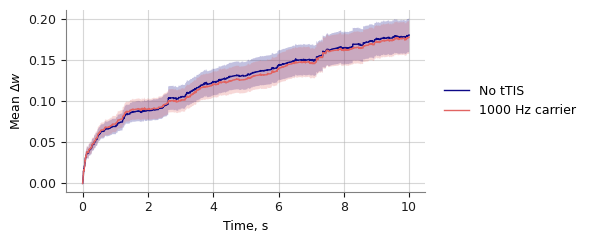

In [16]:
fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (6, 2.5))

ax = axs
for stimulation in weights.keys():
  w = np.abs(weights[stimulation] - 0.1)

  time = w.index / 1000
  mean = np.mean(w, axis = 1)
  error = w.std(axis = 1) / np.sqrt(w.shape[1])

  ax.plot(
    time,
    mean,
    label = stimulation,
    color = colors[stimulation],
    linewidth = 1,
    zorder = 5
  )

  ax.fill_between(
    time,
    mean - error,
    mean + error,
    color = colors[stimulation],
    alpha = 0.25,
    edgecolor = None,
    zorder = 2
  )

ax.set_ylabel(rf"Mean $\Delta w$")
ax.set_xlabel("Time, s")

ax.legend(
  bbox_to_anchor = (1.02, 0.5),
  loc = "center left",
  frameon = False
)

format_ax(ax)

plt.tight_layout()
plt.show()

In [59]:
change = weight_categories.copy()
change.Weight = abs(change.Weight - 0.1)

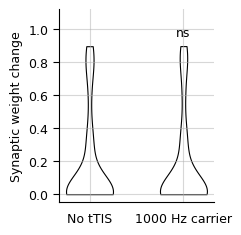

In [61]:
fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (2, 2.5))
ax = axs

frequency = change
grouped = list(frequency.groupby("Stimulation"))
labels = [name for name, _ in grouped]
groups = [g["Weight"].values for _, g in grouped]

# reorder
priority = ["No tTIS"]
order = priority + [l for l in labels if l not in priority]

label_to_group = dict(zip(labels, groups))
labels = order
groups = [label_to_group[l] for l in labels]

# violin plot
vp = ax.violinplot(
  groups,
  showmeans=False,
  showmedians=False,
  showextrema=False
)

# style violins
for body in vp["bodies"]:
  body.set_facecolor("white")
  body.set_edgecolor("black")
  body.set_linewidth(0.8)
  body.set_alpha(1)

# ticks
ax.set_xticks(range(1, len(labels) + 1))
ax.set_xticklabels(labels)

ax.set_ylabel("Synaptic weight change")
ax.set_xlabel("")

ax.xaxis.set_ticks_position("bottom")
ax.yaxis.set_ticks_position("left")
ax.tick_params(axis="x", bottom=False, top=False, length=4)
ax.tick_params(axis="y", left=True, right=False, length=4)

# stats vs No tTIS
ref_idx = labels.index("No tTIS")

y_max = max([g.max() for g in groups])
y_offset = 0.05 * y_max

for i in range(len(groups)):
  if i == ref_idx:
    continue

  stat, p_val = stats.ks_2samp(groups[ref_idx], groups[i], alternative="two-sided")
  stars = p_to_stars(p_val)

  x = i + 1
  y = groups[i].max() + y_offset

  ax.text(x, y, stars, ha="center", va="bottom")

ax.set_ylim(top=y_max + 5 * y_offset)

for spine in ["bottom", "left"]:
  ax.spines[spine].set_visible(True)

for spine in ["top", "right"]:
  ax.spines[spine].set_visible(False)

ax.grid(alpha = 0.5)

In [43]:
# Somatic firing frequency
somatic_firing = list()
cell_ids = np.arange(0, 20)
frequency = 5
for cell_id in cell_ids:
  for stim in stimulations_dict.keys():      
    filename = f"output/temporal-interference-1/{cell_id}/random_poisson/{frequency}/{stim}/spike_frequency.csv"
    n_spikes = len(pd.read_csv(filename, index_col = 0))
    spike_freq = n_spikes / 10

    somatic_firing.append(
      pd.DataFrame({
        "Amplitude": [stimulations_dict[ stim ]],
        "Frequency": [spike_freq]
      })
    )

somatic_firing = pd.concat(somatic_firing)

dendritic_spike_threshold = 0
# Dendritic firing frequency
dendritic_firing = list()
for stim in stimulations_dict.keys():
  print(f"Processing stimulation: {stim}")
  spike_counts = []
  for cell_id in cell_ids:
    filename = f"output/temporal-interference-1/{cell_id}/random_poisson/{frequency}/{stim}/synapse_voltage.csv"
    synapse_voltage = pd.read_csv(filename, index_col=0)

    syn_v = synapse_voltage[synapse_cols].to_numpy()

    spikes = (syn_v[:-1, :] >= dendritic_spike_threshold) & (syn_v[1:, :] < dendritic_spike_threshold)
    counts = np.sum(spikes, axis=0)

    spike_counts.extend(counts.tolist())

  dendritic_firing.append(
    pd.DataFrame({
      "Amplitude": stimulations_dict[ stim ],
      "Frequency": np.array(spike_counts) / 10
    })
  )

dendritic_firing = pd.concat(dendritic_firing)

Processing stimulation: noTI_0.1
Processing stimulation: 1000_0_0.26_0.1


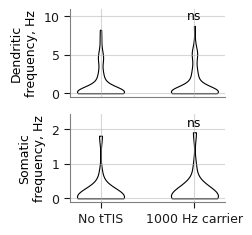

In [46]:
fig, axs = plt.subplots(nrows = 2, ncols = 1, figsize = (2, 2.5), sharex = True)

################## Somatic firing frequency

frequency = dendritic_firing
grouped = list(frequency.groupby("Amplitude"))
labels = [name for name, _ in grouped]
groups = [g["Frequency"].values for _, g in grouped]

# reorder
priority = ["No tTIS"]
order = priority + [l for l in labels if l not in priority]

label_to_group = dict(zip(labels, groups))
labels = order
groups = [label_to_group[l] for l in labels]

# violin plot
vp = axs[0].violinplot(
  groups,
  showmeans=False,
  showmedians=False,
  showextrema=False
)

# style violins
for body in vp["bodies"]:
  body.set_facecolor("white")
  body.set_edgecolor("black")
  body.set_linewidth(0.8)
  body.set_alpha(1)

# ticks
# axs[0].set_xticks(range(1, len(labels) + 1))
# axs[0].set_xticklabels(labels)

axs[0].set_ylabel("Dendritic\nfrequency, Hz")
axs[0].set_xlabel("")

axs[0].xaxis.set_ticks_position("bottom")
axs[0].yaxis.set_ticks_position("left")
axs[0].tick_params(axis="x", bottom=False, top=False, length=4)
axs[0].tick_params(axis="y", left=True, right=False, length=4)

# stats vs No tTIS
ref_idx = labels.index("No tTIS")

y_max = max([g.max() for g in groups])
y_offset = 0.05 * y_max

for i in range(len(groups)):
  if i == ref_idx:
    continue

  stat, p_val = stats.mannwhitneyu(groups[ref_idx], groups[i], alternative="two-sided")
  stars = p_to_stars(p_val)

  x = i + 1
  y = groups[i].max() + y_offset

  axs[0].text(x, y, stars, ha="center", va="bottom")

axs[0].set_ylim(top=y_max + 5 * y_offset)

for spine in ["bottom", "left"]:
  axs[0].spines[spine].set_visible(True)

for spine in ["top", "right"]:
  axs[0].spines[spine].set_visible(False)

axs[0].grid(alpha = 0.5)

####################### Dendritic firing frequency

frequency = somatic_firing
grouped = list(frequency.groupby("Amplitude"))
labels = [name for name, _ in grouped]
groups = [g["Frequency"].values for _, g in grouped]

# reorder
priority = ["No tTIS"]
order = priority + [l for l in labels if l not in priority]

label_to_group = dict(zip(labels, groups))
labels = order
groups = [label_to_group[l] for l in labels]

# violin plot
vp = axs[1].violinplot(
  groups,
  showmeans=False,
  showmedians=False,
  showextrema=False
)

# style violins
for body in vp["bodies"]:
  body.set_facecolor("white")
  body.set_edgecolor("black")
  body.set_linewidth(0.8)
  body.set_alpha(1)

# ticks
axs[1].set_xticks(range(1, len(labels) + 1))
axs[1].set_xticklabels(labels)

axs[1].set_ylabel("Somatic\nfrequency, Hz")
axs[1].set_xlabel("")

axs[1].xaxis.set_ticks_position("bottom")
axs[1].yaxis.set_ticks_position("left")
axs[1].tick_params(axis="x", bottom=True, top=False, length=4)
axs[1].tick_params(axis="y", left=True, right=False, length=4)

# stats vs No TI
ref_idx = labels.index("No tTIS")

y_max = max([g.max() for g in groups])
y_offset = 0.05 * y_max

for i in range(len(groups)):
  if i == ref_idx:
    continue

  stat, p_val = stats.mannwhitneyu(groups[ref_idx], groups[i], alternative="two-sided")
  stars = p_to_stars(p_val)

  x = i + 1
  y = groups[i].max() + y_offset

  axs[1].text(x, y, stars, ha="center", va="bottom")

axs[1].set_ylim(top=y_max + 5.5 * y_offset)

for spine in ["bottom", "left"]:
  axs[1].spines[spine].set_visible(True)

for spine in ["top", "right"]:
  axs[1].spines[spine].set_visible(False)

axs[1].grid(alpha = 0.5)

axs[0].tick_params(bottom = False, labelbottom = False)

for ax in axs:
  for spine in ax.spines.values():
    spine.set_color("gray")

  ax.tick_params(axis="both", colors="#1a1a1a")


In [49]:
from scipy.stats import chi2_contingency

counts = (
  weight_categories
  .groupby(["Stimulation", "Category"], observed = True)
  .size()
  .unstack(fill_value=0)
)

no_ti = counts.loc["No tTIS"].values

final_weight_category_p = {}

for condition in counts.index:
  if condition == "No tTIS":
    continue
  
  other = counts.loc[condition].values
  table = np.vstack([no_ti, other])
  
  chi2, p, dof, expected = chi2_contingency(table)
  final_weight_category_p[condition] = p

final_weight_category_stars = { condition: p_to_stars(p) for condition, p in final_weight_category_p.items() }
final_weight_category_stars

{'1000 Hz carrier': 'ns'}

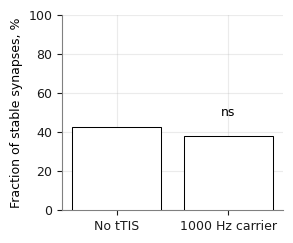

In [58]:
category_counts = (
  weight_categories
  .groupby(["Stimulation", "Category"], observed = True)
  .size()
  .reset_index(name = "Count")
)

category_counts = category_counts[ category_counts.Category == "Stable" ]

category_counts["Stimulation"] = pd.Categorical(
    category_counts["Stimulation"],
    categories = ["No tTIS", "1000 Hz carrier"],
    ordered = True
)

category_counts = category_counts.sort_values("Stimulation")

fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (3, 2.5))
ax = axs

ax.bar(
  category_counts.Stimulation,
  category_counts.Count / 200 * 100,
  color = "white",
  edgecolor = "black",
  zorder = 5,
  linewidth = 0.75
)

ax.grid(alpha = 0.25, zorder = 0)

ax.set_ylabel("Fraction of stable synapses, %")

ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

for spine in ax.spines.values():
  spine.set_color("gray")

ax.tick_params(axis="both", colors="#1a1a1a")

for intensity in final_weight_category_stars.keys():
  height = 50
  ax.text(
    intensity, height,
    final_weight_category_stars[ intensity ],
    va = "center",
    ha = "center"
  )

ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()